In [ ]:
%matplotlib inline
import numpy as np
import cv2
import copy
import matplotlib.image as mpimg
from matplotlib import pyplot as plt
from sklearn.cluster import KMeans
import os
import glob

Text(0.5, 1.0, 'Own')

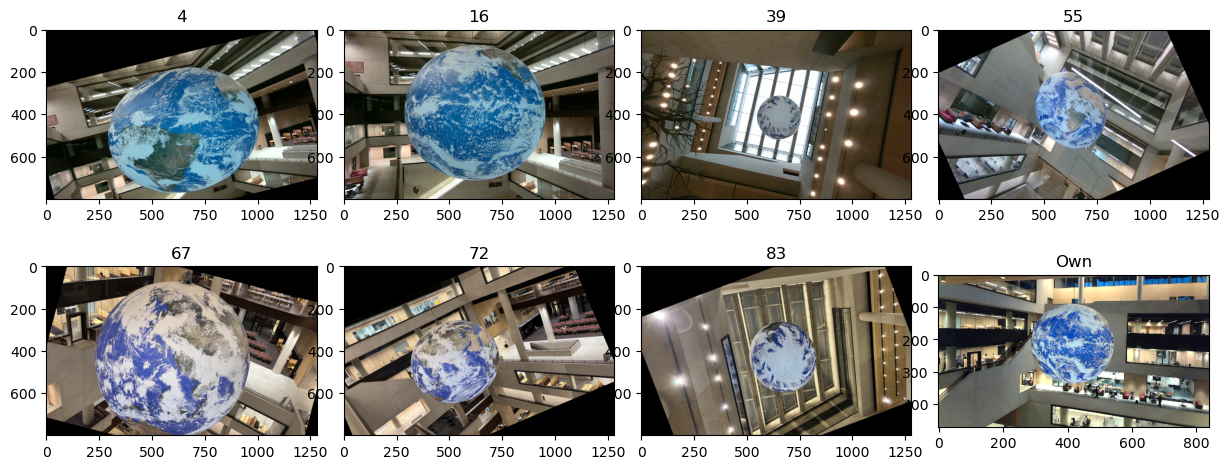

In [15]:
# Load selected sample images from the Easy and Own datasets
img_1 = cv2.imread('../Dataset_25/Easy/images/000004.png')
img_2 = cv2.imread('../Dataset_25/Easy/images/000016.png')
img_3 = cv2.imread('../Dataset_25/Easy/images/000039.png')
img_4 = cv2.imread('../Dataset_25/Easy/images/000055.png')
img_5 = cv2.imread('../Dataset_25/Easy/images/000067.png')
img_6 = cv2.imread('../Dataset_25/Easy/images/000072.png')
img_7 = cv2.imread('../Dataset_25/Easy/images/000083.png')
img_8 = cv2.imread('../Dataset_25/Own/images/000004.png')

# Convert BGR images to RGB 
rgb_1 = cv2.cvtColor(img_1, cv2.COLOR_BGR2RGB)
rgb_2 = cv2.cvtColor(img_2, cv2.COLOR_BGR2RGB)
rgb_3 = cv2.cvtColor(img_3, cv2.COLOR_BGR2RGB)
rgb_4 = cv2.cvtColor(img_4, cv2.COLOR_BGR2RGB)
rgb_5 = cv2.cvtColor(img_5, cv2.COLOR_BGR2RGB)
rgb_6 = cv2.cvtColor(img_6, cv2.COLOR_BGR2RGB)
rgb_7 = cv2.cvtColor(img_7, cv2.COLOR_BGR2RGB)
rgb_8 = cv2.cvtColor(img_8, cv2.COLOR_BGR2RGB)

# Convert images to grayscale
gray_1 = cv2.cvtColor(img_1, cv2.COLOR_BGR2GRAY)
gray_2 = cv2.cvtColor(img_2, cv2.COLOR_BGR2GRAY)
gray_3 = cv2.cvtColor(img_3, cv2.COLOR_BGR2GRAY)
gray_4 = cv2.cvtColor(img_4, cv2.COLOR_BGR2GRAY)
gray_5 = cv2.cvtColor(img_5, cv2.COLOR_BGR2GRAY)
gray_6 = cv2.cvtColor(img_6, cv2.COLOR_BGR2GRAY)
gray_7 = cv2.cvtColor(img_7, cv2.COLOR_BGR2GRAY)
gray_8 = cv2.cvtColor(img_8, cv2.COLOR_BGR2GRAY)

# Load ground truth segmentation masks
gt_mask_1 = cv2.imread('../Dataset_25/Easy/masks/000004.png', cv2.IMREAD_GRAYSCALE)
gt_mask_2 = cv2.imread('../Dataset_25/Easy/masks/000016.png', cv2.IMREAD_GRAYSCALE)
gt_mask_3 = cv2.imread('../Dataset_25/Easy/masks/000039.png', cv2.IMREAD_GRAYSCALE)
gt_mask_4 = cv2.imread('../Dataset_25/Easy/masks/000055.png', cv2.IMREAD_GRAYSCALE)
gt_mask_5 = cv2.imread('../Dataset_25/Easy/masks/000067.png', cv2.IMREAD_GRAYSCALE)
gt_mask_6 = cv2.imread('../Dataset_25/Easy/masks/000072.png', cv2.IMREAD_GRAYSCALE)
gt_mask_7 = cv2.imread('../Dataset_25/Easy/masks/000083.png', cv2.IMREAD_GRAYSCALE)
gt_mask_8 = cv2.imread('../Dataset_25/Own/masks/000004.png', cv2.IMREAD_GRAYSCALE)

fig, axis = plt.subplots(2, 4, figsize=(15,6))
fig.subplots_adjust(wspace=0.1, hspace=0.05)
axis[0][0].imshow(rgb_1)
axis[0][0].set_title('4')

axis[0][1].imshow(rgb_2)
axis[0][1].set_title('16')

axis[0][2].imshow(rgb_3)
axis[0][2].set_title('39')

axis[0][3].imshow(rgb_4)
axis[0][3].set_title('55')

axis[1][0].imshow(rgb_5)
axis[1][0].set_title('67')

axis[1][1].imshow(rgb_6)
axis[1][1].set_title('72')

axis[1][2].imshow(rgb_7)
axis[1][2].set_title('83')

axis[1][3].imshow(rgb_8)
axis[1][3].set_title('Own')

In [16]:
def watershed(src_img, blue_threshold, plot_process):

    # Blue dominance preprocessing
    b, g, r = cv2.split(src_img)
    blue_score = b.astype(np.int16) - ((r.astype(np.int16) + g.astype(np.int16)) // 2)
    blue_score = np.clip(blue_score + 128, 0, 255).astype(np.uint8)
    blue_blur = cv2.GaussianBlur(blue_score, (7, 7), 0)

    # Threshold to keep strong blue pixels as white
    T_blue = blue_threshold 
    _, blue_bin = cv2.threshold(blue_blur, T_blue, 255, cv2.THRESH_BINARY)

    # Decide whether fragments should be glued or split
    contours, _ = cv2.findContours(blue_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    significant_contours = [c for c in contours if cv2.contourArea(c) > 500]
    should_glue = False # Default to NO glue (safer for cluttered images)
    if len(significant_contours) > 0:
        all_points = np.vstack(significant_contours)
        
        # Solidity measures how compact the group of regions is
        hull = cv2.convexHull(all_points)
        hull_area = cv2.contourArea(hull)
        total_blue_area = sum(cv2.contourArea(c) for c in significant_contours)
        solidity = 0
        if hull_area > 0:
            solidity = total_blue_area / float(hull_area)
            
        # Centrality ensures the object is not side clutter
        x, y, w, h = cv2.boundingRect(all_points)
        group_center_x = x + w/2
        image_center_x = blue_bin.shape[1] / 2
        dist_from_center = abs(group_center_x - image_center_x)

        is_dense = solidity > 0.5
        is_central = dist_from_center < (blue_bin.shape[1] / 3.5)
        
        if is_dense and is_central:
            should_glue = True

    # Apply morphology based on the decision
    if should_glue:
        kernel_glue = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))
        blue_clean = cv2.morphologyEx(blue_bin, cv2.MORPH_CLOSE, kernel_glue)
    else:
        kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (17, 17))
        blue_clean = cv2.morphologyEx(blue_bin, cv2.MORPH_OPEN, kernel_open)

    
    
    if plot_process:
        fig, ax = plt.subplots(1, 4, figsize=(18, 4))
        ax[0].imshow(src_img);          ax[0].set_title('Original');            ax[0].axis('off')
        ax[1].imshow(blue_score, cmap='gray'); ax[1].set_title('Blue-dominance');   ax[1].axis('off')
        ax[2].imshow(blue_blur,  cmap='gray'); ax[2].set_title('Blue-dominance (blurred)'); ax[2].axis('off')
        ax[3].imshow(blue_bin, cmap='gray'); ax[3].set_title(f'Binary mask (T = {T_blue})')
        plt.tight_layout()
        plt.show()

    # Connected components: select largest blue region
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(blue_clean)
    if num_labels <= 1:
        num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(blue_bin)

    if num_labels <= 1:
        empty_mask = np.zeros(src_img.shape[:2], dtype=np.uint8)
        return src_img, empty_mask

    areas = stats[1:, cv2.CC_STAT_AREA]
    largest_label = 1 + np.argmax(areas)

    #  Create markers for watershed segmentation
    markers = np.ones_like(labels, dtype=np.int32)
    markers[labels == largest_label] = 2

    if plot_process:
        fig, ax = plt.subplots(1, 2, figsize=(12, 4))
        ax[0].imshow(blue_bin, cmap='gray'); ax[0].set_title('Blue-based binary mask')
        ax[1].imshow(markers, cmap='jet');   ax[1].set_title('Markers (1 = bg, 2 = globe)'); ax[1].axis('off')
        plt.tight_layout()
        plt.show()

    # Watershed refinement
    markers_ws = cv2.watershed(src_img, markers)
    ao_mask = np.uint8(markers_ws == 2) * 255

    kernel_small = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    ao_mask = cv2.morphologyEx(ao_mask, cv2.MORPH_CLOSE, kernel_small)

    # Smooth final mask using circle or ellipse fitting 
    contours, _ = cv2.findContours(ao_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    shape_type = None   

    if len(contours) > 0:
        cnt = max(contours, key=cv2.contourArea)

        if len(cnt) >= 5:

            hull = cv2.convexHull(cnt)
        
            if len(hull) > 4: ellipse = cv2.fitEllipse(hull)  
            else: ellipse = cv2.fitEllipse(cnt)   
            
            (cx, cy), (MA, ma), angle = ellipse
            axis_ratio = max(MA, ma) / min(MA, ma)

            ao_mask_smooth = np.zeros_like(ao_mask)

            if axis_ratio < 1.05:

                radius = int((MA + ma) / 4.0)        
                center = (int(cx), int(cy))
                cv2.circle(ao_mask_smooth, center, radius, 255, -1)
                shape_type = "circle"
                circle_center, circle_radius = center, radius
            else:
                cv2.ellipse(ao_mask_smooth, ellipse, 255, -1)
                shape_type = "ellipse"

            ao_mask = ao_mask_smooth

    # Overlay the fitted boundary on the original image
    overlay_bgr = src_img

    if shape_type == "circle":
        cv2.circle(overlay_bgr, circle_center, circle_radius, (0, 0, 255), 3)
    elif shape_type == "ellipse":
        cv2.ellipse(overlay_bgr, ellipse, (0, 0, 255), 3)

    overlay = cv2.cvtColor(overlay_bgr, cv2.COLOR_BGR2RGB)

    return overlay, ao_mask

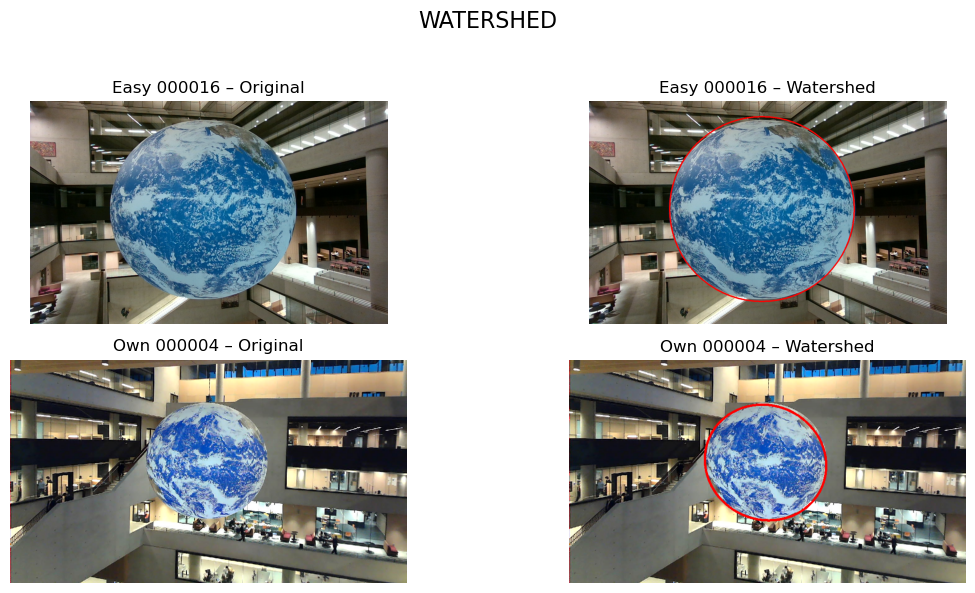

In [17]:
# Images used to evaluate the watershed method
test_imgs = [
    ("Easy 000016", img_2),
    ("Own 000004", img_8)
]

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
fig.subplots_adjust(wspace=0.15, hspace=0.25)
fig.suptitle("WATERSHED", fontsize=16)

WS_T = 135  

for row, (title, bgr_img) in enumerate(test_imgs):

    # Convert for correct display
    orig_rgb = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)
    
    # Apply watershed segmentation
    overlay, ao_mask = watershed(bgr_img.copy(), WS_T, False)

    axes[row, 0].imshow(orig_rgb)
    axes[row, 0].set_title(f"{title} – Original")
    axes[row, 0].axis("off")

    
    axes[row, 1].imshow(overlay)
    axes[row, 1].set_title(f"{title} – Watershed")
    axes[row, 1].axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [18]:
def preprocessing(img):

    # Normalize illumination and reduce shadows using LAB space
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2Lab) 

    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    l = clahe.apply(l)
    lab_eq = cv2.merge((l, a, b))

    lab_eq = cv2.cvtColor(lab_eq, cv2.COLOR_Lab2RGB)

    # Smooth to suppress internal edges
    processed_img = cv2.GaussianBlur(lab_eq, (9, 9), 0) # avoid strong edges inside AO

    return processed_img

def get_kmeans(preprocessed_img, n_clusters):

    # Apply K-means clustering in RGB space
    img_flat = preprocessed_img.reshape(-1, 3)
    kmeans = KMeans(n_clusters=n_clusters, random_state=0).fit(img_flat)

    H, W, _ = preprocessed_img.shape
    labels_img = kmeans.labels_.reshape(H, W)

    return labels_img

def remove_bg(labels_img, rgb):

    # Select the cluster most likely corresponding to the globe
    h, w = labels_img.shape[:2]
    final_mask = np.zeros((h, w), dtype=np.uint8)
    
    center_y_min, center_y_max = int(h * 0.25), int(h * 0.75)
    center_x_min, center_x_max = int(w * 0.25), int(w * 0.75)
    
    unique_labels = np.unique(labels_img)

    biggest_cluster_ratio = -1
    main_cluster = -1

    for i in unique_labels:
        mask = (labels_img == i).astype(np.uint8) * 255

        rgb_masked = cv2.bitwise_and(rgb, rgb, mask=mask)

        total_pixels = np.count_nonzero(mask)

        red_avg = np.sum(rgb_masked[:, :, 0]) / total_pixels
        
        if total_pixels == 0 or red_avg > 100: continue
        
        central_region = mask[center_y_min:center_y_max, center_x_min:center_x_max]
        
        central_pixels = np.count_nonzero(central_region)
        
        density_ratio = central_pixels / total_pixels

        if density_ratio > biggest_cluster_ratio:

            biggest_cluster_ratio = density_ratio
            main_cluster = i
    
    final_mask = (labels_img == main_cluster).astype(np.uint8) * 255

    return final_mask

def show_process(src_img, img_pre, labels_img, closed_mask, ellipse_mask, result_kmeans):

    # Visualise main steps of the K-means pipeline
    fig, axis = plt.subplots(2, 3, figsize=(15, 6))
    axis[0][0].imshow(src_img)
    axis[0][0].set_title('Original')

    axis[0][1].imshow(img_pre)
    axis[0][1].set_title('Preprocessed')

    axis[0][2].imshow(labels_img)
    axis[0][2].set_title('Segmented')

    axis[1][0].imshow(closed_mask, 'gray')
    axis[1][0].set_title('closed mask')

    axis[1][1].imshow(ellipse_mask, 'gray')
    axis[1][1].set_title('ellipse mask')

    axis[1][2].imshow(result_kmeans)
    axis[1][2].set_title('result')

    return None

def kmeans_segmentation(src_img, threshold, clusters, plot):

    # Full K-means based segmentation pipeline
    img_pre = preprocessing(src_img)
    n_clusters = clusters
    labels_img = get_kmeans(img_pre, n_clusters)
    kmeans_mask = remove_bg(labels_img, src_img.copy())

    # Morphological cleanup
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    closed_mask = cv2.morphologyEx(kmeans_mask, cv2.MORPH_CLOSE, kernel)

    # Remove outliers based on distance from center of mass
    closed_mask_points = cv2.findNonZero(closed_mask)
    hull_mask = np.zeros((src_img.shape[0], src_img.shape[1]), dtype=np.uint8)
    points_array = closed_mask_points.reshape(-1, 2)

    center_of_mass = np.mean(points_array, axis=0)
    distances = np.linalg.norm(points_array - center_of_mass, axis=1)

    threshold_distance = np.percentile(distances, threshold)
    points_to_keep_mask = distances <= threshold_distance
    kept_points = points_array[points_to_keep_mask]

    # Remove outliers based on distance from center of mass
    convex_hull = cv2.convexHull(kept_points)
    hull_mask = cv2.drawContours(hull_mask, [convex_hull], -1, 255, thickness=cv2.FILLED)

    if len(convex_hull) > 4: ellipse_kmeans = cv2.fitEllipse(convex_hull)
    else: ellipse_kmeans = cv2.fitEllipse(kept_points)

    ellipse_mask = np.zeros((src_img.shape[0], src_img.shape[1]), dtype=np.uint8)
    ellipse_mask = cv2.ellipse(ellipse_mask, ellipse_kmeans, 255, -1)

    result_kmeans = cv2.ellipse(src_img, ellipse_kmeans, (255, 0, 0), 2)

    if plot:

        show_process(src_img, img_pre, labels_img, closed_mask, ellipse_mask, result_kmeans)

    return result_kmeans, ellipse_mask

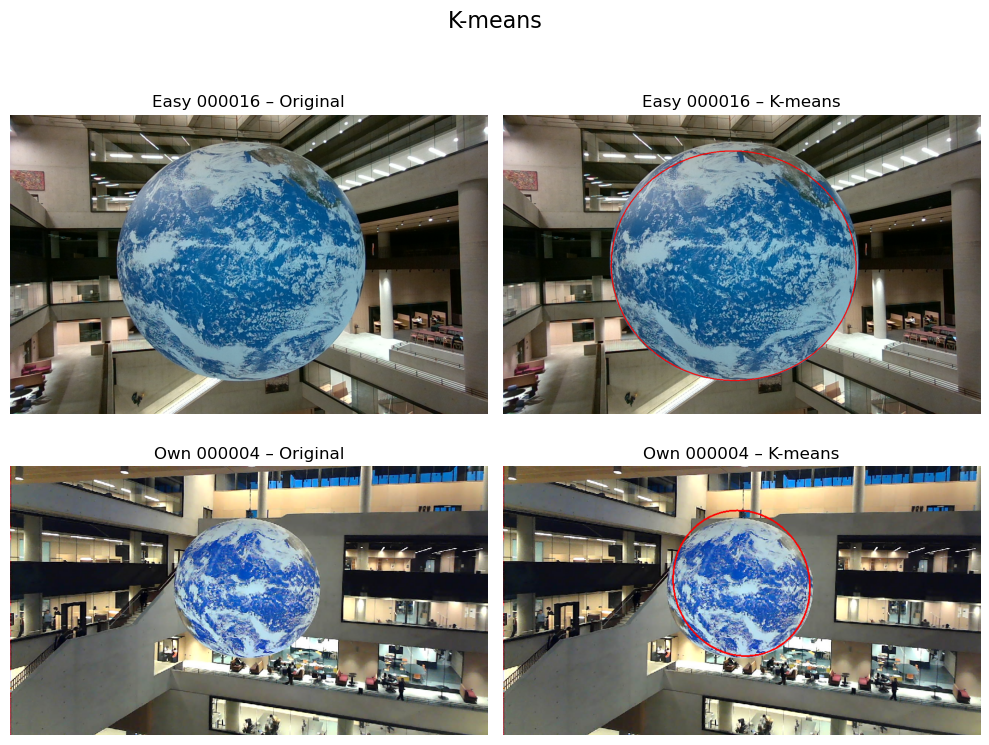

In [19]:
KM_CLUSTERS  = 5

# Test images and thresholds for K-means segmentation
test_imgs_km = [
    ("Easy 000016", rgb_2, 99),   
    ("Own 000004", rgb_8, 83)     
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
fig.subplots_adjust(wspace=0.1, hspace=0.25)
fig.suptitle("K-means", fontsize=16)

for row, (title, rgb_img, km_th) in enumerate(test_imgs_km):
    
    axes[row, 0].imshow(rgb_img)
    axes[row, 0].set_title(f"{title} – Original")
    axes[row, 0].axis("off")

for row, (title, rgb_img, km_th) in enumerate(test_imgs_km):
    
    # Apply K-means segmentation
    km_overlay, km_mask = kmeans_segmentation(rgb_img.copy(),
                                              km_th,
                                              KM_CLUSTERS,
                                              False)

    
    axes[row, 1].imshow(km_overlay)
    axes[row, 1].set_title(f"{title} – K-means")
    axes[row, 1].axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [20]:
def segment_globe_regiongrow_shape_param(src_rgb, white_v_min=170, plot_process=False):
   
    H, W = src_rgb.shape[:2]

    # Preprocess 
    pre = preprocess_for_globe(src_rgb)

    # Colour prior for globe (blue and white)
    hsv = cv2.cvtColor(pre, cv2.COLOR_RGB2HSV)
 
    lower_blue  = np.array([90, 40, 40], np.uint8)
    upper_blue  = np.array([150, 255, 255], np.uint8)
    blue_mask   = cv2.inRange(hsv, lower_blue, upper_blue)

    lower_white = np.array([0, 0, white_v_min], np.uint8)
    upper_white = np.array([179, 80, 255], np.uint8)
    white_mask  = cv2.inRange(hsv, lower_white, upper_white)

    globe_prior = cv2.bitwise_or(blue_mask, white_mask)

    # Morphological to clean the mask
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
    globe_prior = cv2.morphologyEx(globe_prior, cv2.MORPH_CLOSE, kernel, 2)
    globe_prior = cv2.morphologyEx(globe_prior, cv2.MORPH_OPEN,  kernel, 1)

    # Reduce false positives by restricting to the central area
    central = np.zeros_like(globe_prior)
    cx_min, cx_max = int(0.05 * W), int(0.95 * W)
    cy_min, cy_max = int(0.05 * H), int(0.95 * H)
    central[cy_min:cy_max, cx_min:cx_max] = 255
    globe_prior = cv2.bitwise_and(globe_prior, central)

    # Seed from the prior
    ys, xs = np.where(globe_prior > 0)
    if len(xs) > 0:
        seed_x = int(np.mean(xs))
        seed_y = int(np.mean(ys))
    else:
        seed_x, seed_y = W // 2, H // 2

    prior_bin = (globe_prior > 0).astype(np.uint8)
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        prior_bin, connectivity=8
    )

    # Connected component containing the seed
    label_at_seed = labels[seed_y, seed_x] if 0 <= seed_y < H and 0 <= seed_x < W else 0

    region_mask = np.zeros((H, W), np.uint8)
    if label_at_seed != 0:
        region_mask[labels == label_at_seed] = 255
    else:
        region_mask = globe_prior.copy()

    region_mask = cv2.morphologyEx(region_mask, cv2.MORPH_CLOSE, kernel, 2)

    # Fit circle to get a smooth mask
    contours, _ = cv2.findContours(region_mask, cv2.RETR_EXTERNAL,
                                   cv2.CHAIN_APPROX_SIMPLE)

    if len(contours) == 0:
        overlay_rgb = src_rgb.copy()
        final_mask = np.zeros((H, W), np.uint8)
        info = {"seed_point": (seed_x, seed_y), "circle": None}
        return overlay_rgb, final_mask, info

    cnt = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(cnt)

    M = cv2.moments(cnt)
    if M["m00"] == 0:
        cx, cy = seed_x, seed_y
    else:
        cx = M["m10"] / M["m00"]
        cy = M["m01"] / M["m00"]

    radius = np.sqrt(area / np.pi) * 0.97
    cx_i, cy_i, r_i = int(round(cx)), int(round(cy)), int(round(radius))

    final_mask = np.zeros((H, W), np.uint8)
    cv2.circle(final_mask, (cx_i, cy_i), r_i, 255, -1)

    final_mask = cv2.bitwise_and(final_mask, globe_prior)
    final_mask = cv2.morphologyEx(final_mask, cv2.MORPH_CLOSE, kernel, 1)

    overlay_bgr = cv2.cvtColor(src_rgb, cv2.COLOR_RGB2BGR)
    cv2.circle(overlay_bgr, (cx_i, cy_i), r_i, (0, 0, 255), 3)
    overlay_rgb = cv2.cvtColor(overlay_bgr, cv2.COLOR_BGR2RGB)

    info = {
        "circle_center": (cx, cy),
        "circle_radius": radius,
        "area_region": area,
    }

    return overlay_rgb, final_mask, info

def preprocess_for_globe(src_rgb):

    # Normalise illumination and smooth to stabilise colour thresholds
    lab = cv2.cvtColor(src_rgb, cv2.COLOR_RGB2LAB)
    L, A, B = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    L_eq = clahe.apply(L)
    lab_eq = cv2.merge((L_eq, A, B))
    rgb_eq = cv2.cvtColor(lab_eq, cv2.COLOR_LAB2RGB)
    rgb_blur = cv2.GaussianBlur(rgb_eq, (7, 7), 0)
    return rgb_blur

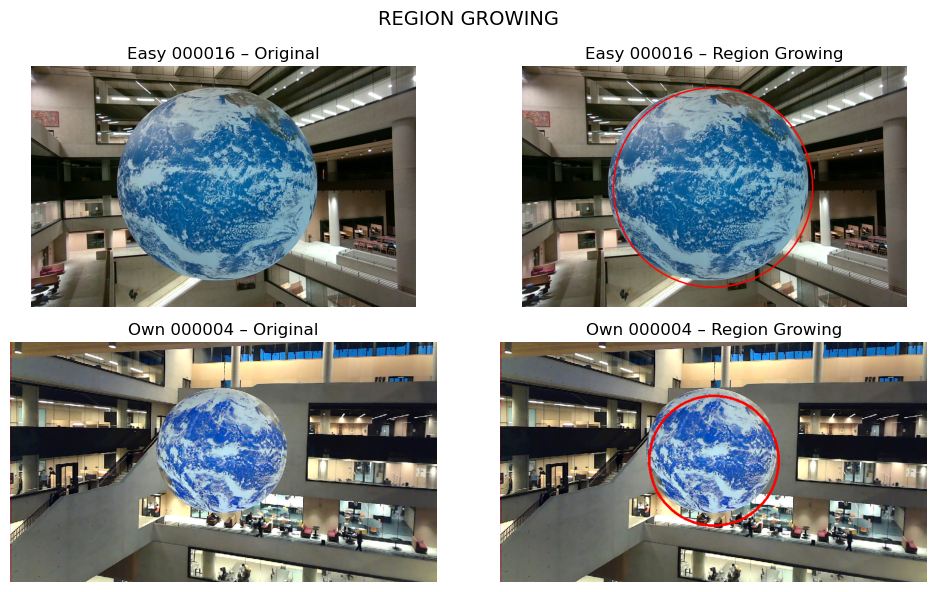

In [21]:
RG_WHITE_V_MIN = 190  

# Test images for evaluating the region growing segmentation
test_imgs_rg = [
    ("Easy 000016", img_2),   
    ("Own 000004", img_8)   
]

fig, axes = plt.subplots(len(test_imgs_rg), 2, figsize=(10, 6))
fig.subplots_adjust(wspace=0.1, hspace=0.25)
fig.suptitle("REGION GROWING", fontsize=14)

for row, (title, bgr_img) in enumerate(test_imgs_rg):
    # Convert to RGB for region-growing (your function expects RGB)
    rgb_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)

    axes[row, 0].imshow(rgb_img)
    axes[row, 0].set_title(f"{title} – Original")
    axes[row, 0].axis("off")

    # Apply region growing segmentation
    rg_overlay, rg_mask, info = segment_globe_regiongrow_shape_param(
        rgb_img.copy(),
        white_v_min=RG_WHITE_V_MIN,
        plot_process=False
    )

    axes[row, 1].imshow(rg_overlay)
    axes[row, 1].set_title(f"{title} – Region Growing")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


In [22]:
# Combined segmentation method (Q1b)
# Fuses watershed, region growing, and K-means results

WS_T = 135         
KM_INTENSITY = 90   
KM_CLUSTERS = 5     

def combined_segmentation(bgr_img):
   
    rgb_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)

    # Run the three independent segmentation methods
    ws_overlay, ws_mask = watershed(bgr_img.copy(), WS_T, False)
    rg_overlay, rg_mask, _ = segment_globe_regiongrow_shape_param(rgb_img.copy(), plot_process=False)
    km_overlay, km_mask = kmeans_segmentation(bgr_img.copy(), KM_INTENSITY, KM_CLUSTERS, False)

    # Convert outputs to binary masks
    ws_bin = ws_mask > 0
    rg_bin = rg_mask > 0
    km_bin = km_mask > 0

    # Voting-based fusion: watershed must agree with at least one other method
    vote_sum = ws_bin.astype(np.int32) * (rg_bin.astype(np.int32) + km_bin.astype(np.int32))
    comb_mask = (vote_sum >= 1).astype(np.uint8) * 255

    # Post-processing
    overlay_comb = cv2.cvtColor(bgr_img.copy(), cv2.COLOR_BGR2RGB)
    clean_mask = np.zeros_like(comb_mask)
    contours, _ = cv2.findContours(comb_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) > 0:
        cnt = max(contours, key=cv2.contourArea)
        hull = cv2.convexHull(cnt)

        # Ellipse fitting if the shape is sufficiently circular
        if len(hull) > 4:
            ellipse = cv2.fitEllipse(hull)
            (center, axes, angle) = ellipse
            (MA, ma) = axes
            aspect_ratio = min(MA, ma) / max(MA, ma)
            if aspect_ratio > 0.3: 
                cv2.ellipse(overlay_comb, ellipse, (255, 0, 0), 2)
                cv2.ellipse(clean_mask, ellipse, 255, -1)
            else:
                # Fallback if ellipse fit is unreliable
                cv2.drawContours(overlay_comb, [hull], -1, (255, 0, 0), 2)
                cv2.drawContours(clean_mask, [hull], -1, 255, -1)
        else:
            print('else')
            cv2.drawContours(overlay_comb, [cnt], -1, (255, 0, 0), 3)  # red outline

    return overlay_comb, clean_mask, ws_mask, rg_mask, km_mask

### Task 1b

In [23]:
def load_test_img(path):

    bgr_img = cv2.imread(path)
    rgb_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)
    gray_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)
    
    return bgr_img, rgb_img, gray_img

def compute_rates(pred_mask, gt_mask):

    pred = pred_mask > 0

    gt = gt_mask > 0

    TP = np.logical_and(pred, gt).sum()
    FP = np.logical_and(pred, ~gt).sum()
    FN = np.logical_and(~pred, gt).sum()
    TN = np.logical_and(~pred, ~gt).sum()

    tpr = TP / (TP + FN)
    fpr = FP / (FP + TN)
    return fpr, tpr


0:
  Watershed     -> FPR = 0.024, TPR = 0.997
  Region-grow   -> FPR = 0.001, TPR = 0.802
  K-means       -> FPR = 0.680, TPR = 1.000
  COMBINED (MV) -> FPR = 0.024, TPR = 0.998

1:
  Watershed     -> FPR = 0.009, TPR = 0.993
  Region-grow   -> FPR = 0.010, TPR = 0.937
  K-means       -> FPR = 0.827, TPR = 1.000
  COMBINED (MV) -> FPR = 0.010, TPR = 0.994

2:
  Watershed     -> FPR = 0.001, TPR = 0.984
  Region-grow   -> FPR = 0.107, TPR = 0.674
  K-means       -> FPR = 0.809, TPR = 1.000
  COMBINED (MV) -> FPR = 0.001, TPR = 0.988

3:
  Watershed     -> FPR = 0.011, TPR = 0.996
  Region-grow   -> FPR = 0.025, TPR = 0.886
  K-means       -> FPR = 0.771, TPR = 1.000
  COMBINED (MV) -> FPR = 0.011, TPR = 0.996

4:
  Watershed     -> FPR = 0.000, TPR = 0.944
  Region-grow   -> FPR = 0.000, TPR = 0.718
  K-means       -> FPR = 0.706, TPR = 1.000
  COMBINED (MV) -> FPR = 0.000, TPR = 0.945

5:
  Watershed     -> FPR = 0.001, TPR = 0.746
  Region-grow   -> FPR = 0.000, TPR = 0.596
  K-mean

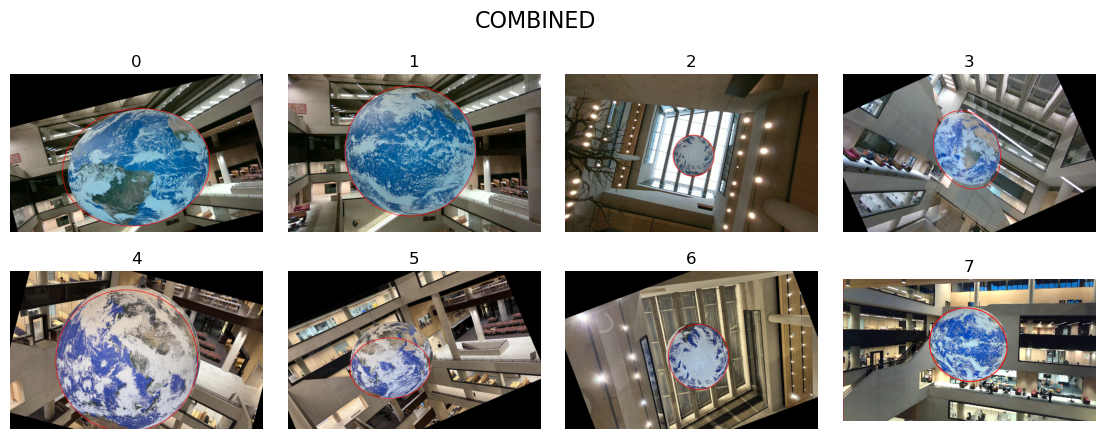

In [24]:
# Run combined segmentation on all images and compare to GT masks

img_array = [img_1, img_2, img_3, img_4, img_5, img_6, img_7, img_8]
gt_array = [gt_mask_1, gt_mask_2, gt_mask_3, gt_mask_4, gt_mask_5, gt_mask_6, gt_mask_7, gt_mask_8]

fig, axis = plt.subplots(2, 4, figsize=(14,5))
fig.subplots_adjust(wspace=0.1, hspace=0.05)
fig.suptitle("COMBINED", fontsize=16)

for i, img in enumerate(img_array):
    # Run combined method and keep individual method masks for reporting
    overlay, ao_mask, ws_mask, rg_mask, km_mask = combined_segmentation(img.copy())

    gt_mask = gt_array[i]

    # Compute FPR/TPR for each method against ground truth
    f_ws, t_ws = compute_rates(ws_mask, gt_mask)
    f_rg, t_rg = compute_rates(rg_mask, gt_mask)
    f_km, t_km = compute_rates(km_mask, gt_mask)
    f_cb, t_cb = compute_rates(ao_mask, gt_mask)
    print(f"\n{i}:")
    print(f"  Watershed     -> FPR = {f_ws:.3f}, TPR = {t_ws:.3f}")
    print(f"  Region-grow   -> FPR = {f_rg:.3f}, TPR = {t_rg:.3f}")
    print(f"  K-means       -> FPR = {f_km:.3f}, TPR = {t_km:.3f}")
    print(f"  COMBINED (MV) -> FPR = {f_cb:.3f}, TPR = {t_cb:.3f}")

    if i < 4:

        row = 0
        col = i

    else:

        row = 1
        col = i - 4
    
    axis[row][col].imshow(overlay)
    axis[row][col].set_title(i)

    for ax in axis.flatten():
        ax.axis('off')


plt.show()

### Task 1c


=== Computing ROC for difficulty: Easy ===


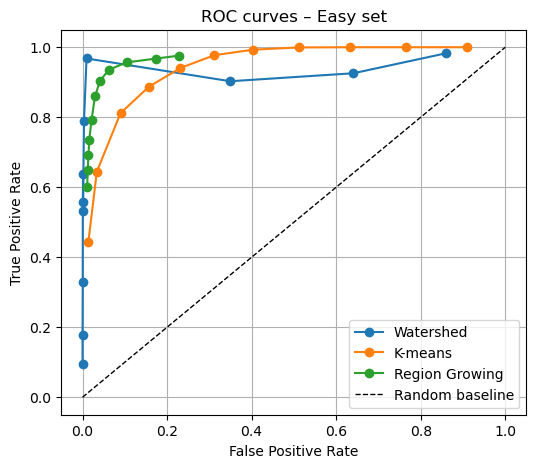


=== Computing ROC for difficulty: Medium ===


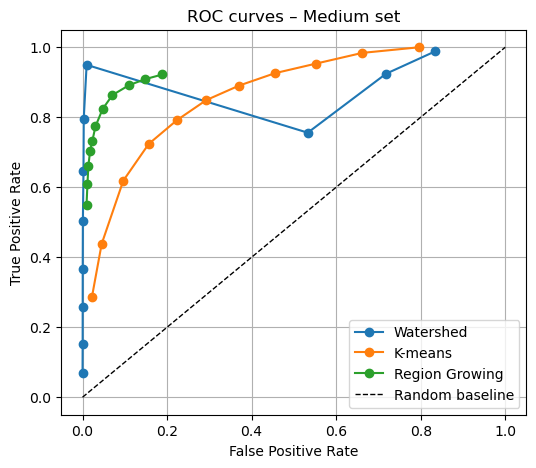


=== Computing ROC for difficulty: Hard ===


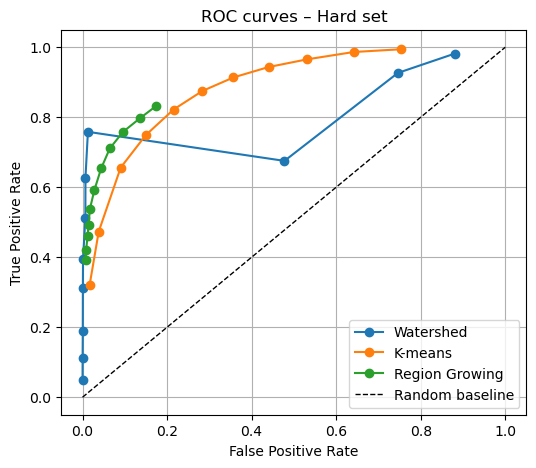

In [25]:
# Parameter grids for ROC sweeps
parameters = {
    'watershed':  [105, 115, 125, 135, 145, 155, 165, 175, 185, 195, 205],
    'kmeans':     [[5, 5], [10, 5], [20, 5], [30, 5], [40, 5], [50, 5], [60, 5], [70, 5], [80, 5], [90, 5], [100, 5]],
    'regiongrow': [90, 105, 120, 135, 150, 165, 180, 195, 210, 225, 240],
}

difficulties = ['Easy', 'Medium', 'Hard']   # one figure per difficulty
methods      = ['watershed', 'kmeans', 'regiongrow']
method_labels = {
    'watershed':  'Watershed',
    'kmeans':     'K-means',
    'regiongrow': 'Region Growing'
}

for folder in difficulties:
    roc_curves = {}

    print(f"\n=== Computing ROC for difficulty: {folder} ===")

    # Sweep method parameters and average performance across all images in the folder
    for method in methods:
        fpr_mean_list = []
        tpr_mean_list = []

        if method == 'watershed':
            param_list = parameters['watershed']
        elif method == 'kmeans':
            param_list = parameters['kmeans']
        else: 
            param_list = parameters['regiongrow']

        for p in param_list:
            fprs = []
            tprs = []

            image_search_pattern = os.path.join('../Dataset_25', folder, 'images', '*.png')

            for image_path in sorted(glob.glob(image_search_pattern)):
                filename = os.path.basename(image_path)
                mask_path = os.path.join('../Dataset_25', folder, 'masks', filename)
                gt_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

                bgr_img, rgb_img, gray_img = load_test_img(image_path)

                # Run the selected method using the current parameter value
                if method == 'watershed':
                    T = p
                    _, pred_mask = watershed(bgr_img.copy(), T, False)

                elif method == 'kmeans':
                    thr, n_clusters = p[0], p[1]
                    _, pred_mask = kmeans_segmentation(bgr_img.copy(), thr, n_clusters, False)

                else: 
                    white_v_min = p
                    _, pred_mask, _ = segment_globe_regiongrow_shape_param(
                        rgb_img.copy(), white_v_min=white_v_min, plot_process=False
                    )

                fpr, tpr = compute_rates(pred_mask, gt_mask)
                fprs.append(fpr)
                tprs.append(tpr)

            fpr_mean_list.append(np.mean(fprs))
            tpr_mean_list.append(np.mean(tprs))

        # Sort points by FPR to form a valid ROC curve
        points = sorted(zip(fpr_mean_list, tpr_mean_list))
        fprs_sorted, tprs_sorted = zip(*points)
        roc_curves[method] = (fprs_sorted, tprs_sorted)

    # Plot the ROC for this difficulty
    plt.figure(figsize=(6, 5))
    for method in methods:
        fprs, tprs = roc_curves[method]
        plt.plot(fprs, tprs, 'o-', label=method_labels[method])

    plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random baseline')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC curves – {folder} set')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()

### Task 1d

In [26]:
def combined_segmentation(bgr_img, t_blue, selected_p):
   
    rgb_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)

    # Run three independent segmentation methods
    ws_overlay, ws_mask = watershed(bgr_img.copy(), t_blue, False)
    rg_overlay, rg_mask, _ = segment_globe_regiongrow_shape_param(rgb_img.copy(), white_v_min=170, plot_process=False)
    km_overlay, km_mask = kmeans_segmentation(bgr_img.copy(), selected_p, 5, False)

    # Convert outputs to binary masks
    ws_bin = ws_mask > 0
    rg_bin = rg_mask > 0
    km_bin = km_mask > 0

    # Voting: watershed must agree with at least one other method
    vote_sum = ws_bin.astype(np.int32) * (rg_bin.astype(np.int32) + km_bin.astype(np.int32))
    comb_mask = (vote_sum >= 1).astype(np.uint8) * 255

    # Enforce a smooth final shape
    overlay_comb = cv2.cvtColor(bgr_img.copy(), cv2.COLOR_BGR2RGB)
    clean_mask = np.zeros_like(comb_mask)
    contours, _ = cv2.findContours(comb_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) > 0:
        cnt = max(contours, key=cv2.contourArea)
        hull = cv2.convexHull(cnt)

        # Ellipse fitting if the shape is sufficiently circular
        if len(hull) > 4:
            ellipse = cv2.fitEllipse(hull)
            (center, axes, angle) = ellipse
            (MA, ma) = axes
            aspect_ratio = min(MA, ma) / max(MA, ma)
            if aspect_ratio > 0.3: 
    
                cv2.ellipse(overlay_comb, ellipse, (255, 0, 0), 2)
                cv2.ellipse(clean_mask, ellipse, 255, -1)
            else:
                # Fallback when ellipse fit is unreliable
                cv2.drawContours(overlay_comb, [hull], -1, (255, 0, 0), 2)
                cv2.drawContours(clean_mask, [hull], -1, 255, -1)
        else:
            print('else')
            cv2.drawContours(overlay_comb, [cnt], -1, (255, 0, 0), 3) 

    return overlay_comb, clean_mask, ws_mask, rg_mask, km_mask

Quantitative parameter searching

In [ ]:
# Parameter grids for combined method tuning
result_path = 'complete' # 'easyIoU'
t_blue = np.array([115, 125, 135, 145, 155, 165, 175])
selected_p = np.array([5, 23, 41, 59, 77, 95])

X, Y = np.meshgrid(t_blue, selected_p)

def load_test_img(path):
    # Load image in BGR, RGB, and grayscale
    bgr_img = cv2.imread(path)
    rgb_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)
    gray_img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)
    
    return bgr_img, rgb_img, gray_img

def compute_rates(pred_mask, gt_mask):
    # Compute Intersection-over-Union (IoU) between prediction and ground truth
    gt = gt_mask > 0
    pred = pred_mask > 0

    TP = np.logical_and(pred, gt).sum()
    FP = np.logical_and(pred, ~gt).sum()
    FN = np.logical_and(~pred, gt).sum()
    TN = np.logical_and(~pred, ~gt).sum()

    IoU = TP / (TP + FP + FN)
    return IoU

# Dataset difficulty levels
d = ['Easy', 'Medium', 'Hard']

# Store mean IoU for each parameter combination
IoU_combined_mean = np.zeros((t_blue.shape[0], selected_p.shape[0]))

# Grid search over watershed and K-means parameters
for idx_t, T in enumerate(t_blue):

    for idx_s, S in enumerate(selected_p):

        IoUs = []

        for folder in d:
            print(f"[Watershed T={T}, K-Means W={S}] Folder: {folder}, t: {idx_t}, T: {T}, w: {idx_s}, W: {S}")

            image_search_pattern = os.path.join('../Dataset_25', folder, 'images', '*.png')

            for image_path in sorted(glob.glob(image_search_pattern)):

                filename = os.path.basename(image_path)

                print(f'file: {image_path}')

                mask_path = os.path.join('../Dataset_25', folder, 'masks', filename)
                gt_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

                bgr_img, rgb_img, gray_img = load_test_img(image_path)

                # Run combined segmentation and evaluate against ground truth
                overlay, ao_mask, ws_mask, rg_mask, km_mask = combined_segmentation(bgr_img.copy(), T, S)

                IoU = compute_rates(ao_mask, gt_mask)
                IoUs.append(IoU)

        # Average IoU across all images and difficulty levels
        IoU_combined_mean[idx_t, idx_s] = np.mean(IoUs)
        print(IoU_combined_mean)

# Save final IoU grid
np.save(result_path, IoU_combined_mean)

Plot heatmap and find the highest point that is the best parameter config

(6, 7)


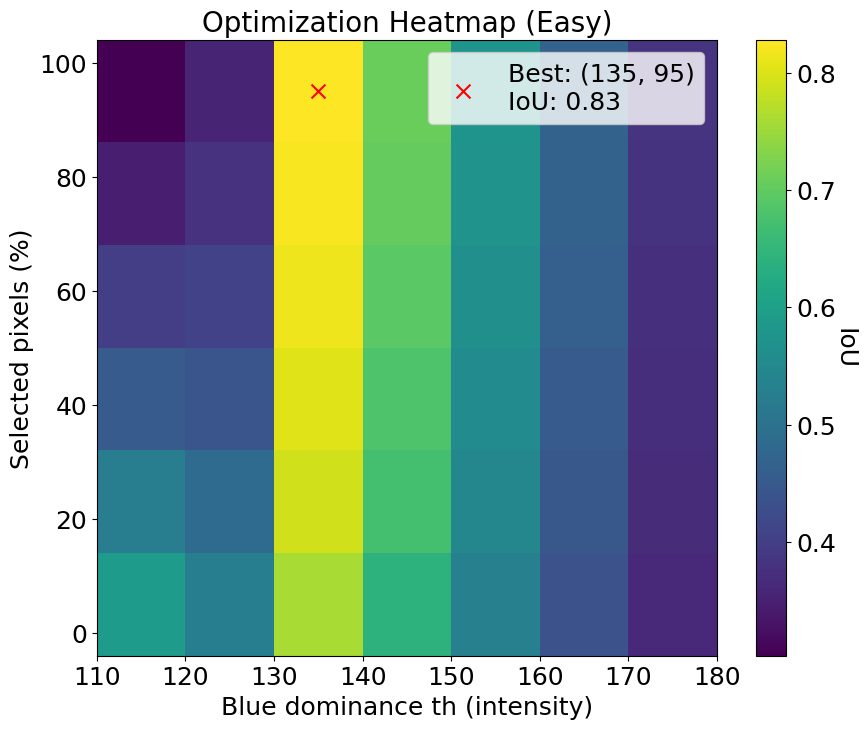

In [27]:
# Parameter grids for optimisation
result_path = 'complete.npy' # 'easyIoU.npy'
t_blue = np.array([115, 125, 135, 145, 155, 165, 175])
selected_p = np.array([5, 23, 41, 59, 77, 95])

X, Y = np.meshgrid(t_blue, selected_p)


# Load precomputed mean IoU results for the combined method
IoU_combined_mean = np.load(result_path).T
print(IoU_combined_mean.shape)

context_settings = {
    'font.size': 18,
    'axes.titlesize': 20,
    'axes.labelsize': 18
}

with plt.rc_context(context_settings):

    # Heatmap of IoU over parameter space
    plt.figure(figsize=(10, 8))
    c = plt.pcolormesh(X, Y, IoU_combined_mean, cmap='viridis', shading='nearest')

    cbar = plt.colorbar(c)
    cbar.set_label('IoU', rotation=270, labelpad=15)

    # Identify best performing parameter combination
    max_idx = np.unravel_index(np.argmax(IoU_combined_mean), IoU_combined_mean.shape)
    best_x = X[max_idx]
    best_y = Y[max_idx]
    max_z = IoU_combined_mean[max_idx]

    plt.scatter(best_x, best_y, color='red', s=100, marker='x', label=f'Best: ({best_x}, {best_y})\nIoU: {max_z:.2f}')

    plt.xlabel('Blue dominance th (intensity)')
    plt.ylabel('Selected pixels (%)')
    plt.title('Optimization Heatmap (Easy)')
    plt.legend(loc='upper right')

    plt.show()

Plot heatmap with gradient field and find the bet pair using both criterions

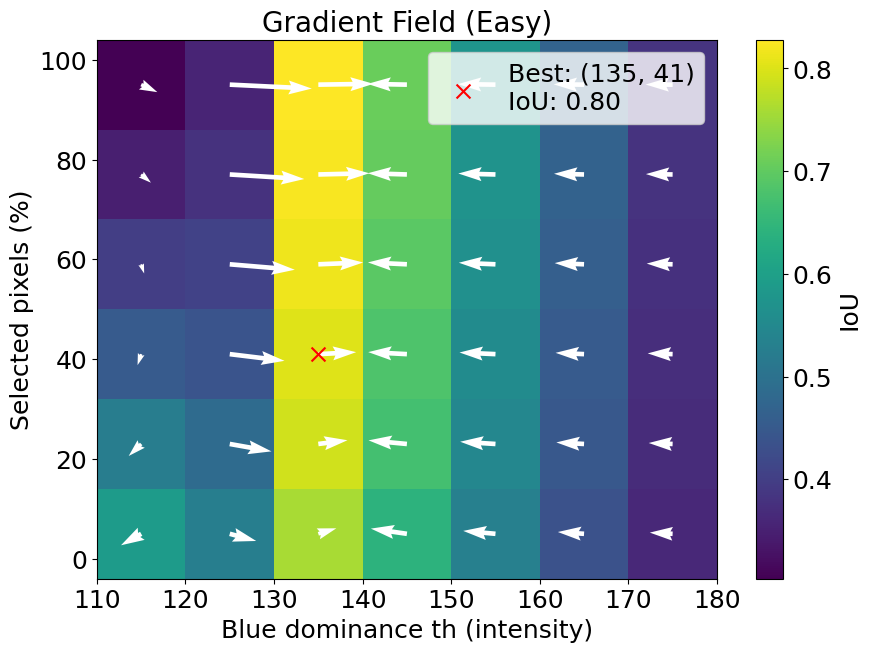

In [28]:
result_path = 'complete.npy' # 'easyIoU.npy'
t_blue = np.array([115, 125, 135, 145, 155, 165, 175])
selected_p = np.array([5, 23, 41, 59, 77, 95])

X, Y = np.meshgrid(t_blue, selected_p)

# Load precomputed IoU surface (Easy set)
IoU_combined_mean = np.load(result_path).T

# Compute spatial gradients of the IoU surface
x_step = t_blue[1] - t_blue[0]
y_step = selected_p[1] - selected_p[0]
grad_y, grad_x = np.gradient(IoU_combined_mean, y_step, x_step)

# Gradient magnitude indicates sensitivity to parameter changes
magnitude = np.sqrt(grad_x**2 + grad_y**2)

# Select parameter pairs close to the maximum IoU
max_iou = np.max(IoU_combined_mean) 
tolerance = 0.03
threshold = max_iou - tolerance
candidates_mask = IoU_combined_mean >= threshold


# Among good performing pairs, choose the flattest (most stable) region
masked_magnitude = np.where(candidates_mask, magnitude, np.inf)
best_idx = np.unravel_index(np.argmin(masked_magnitude), IoU_combined_mean.shape) 
best_x = X[best_idx]
best_y = Y[best_idx]
best_iou = IoU_combined_mean[best_idx]


# Plot IoU surface with gradient field and selected optimal point
context_settings = {
    'font.size': 18,
    'axes.titlesize': 20,
    'axes.labelsize': 18
}

with plt.rc_context(context_settings):
    fig, ax = plt.subplots(figsize=(10, 7))

    c = ax.pcolormesh(X, Y, IoU_combined_mean, shading='auto', cmap='viridis')
    fig.colorbar(c, label='IoU')

    ax.quiver(X, Y, grad_x, grad_y, color='white')

    plt.scatter(best_x, best_y, color='red', s=100, marker='x', label=f'Best: ({best_x}, {best_y})\nIoU: {best_iou:.2f}')

    plt.xlabel('Blue dominance th (intensity)')
    plt.ylabel('Selected pixels (%)')
    ax.set_title('Gradient Field (Easy)')
    plt.legend(loc='upper right')
    plt.show()

Compare parameter pairs in 2 images

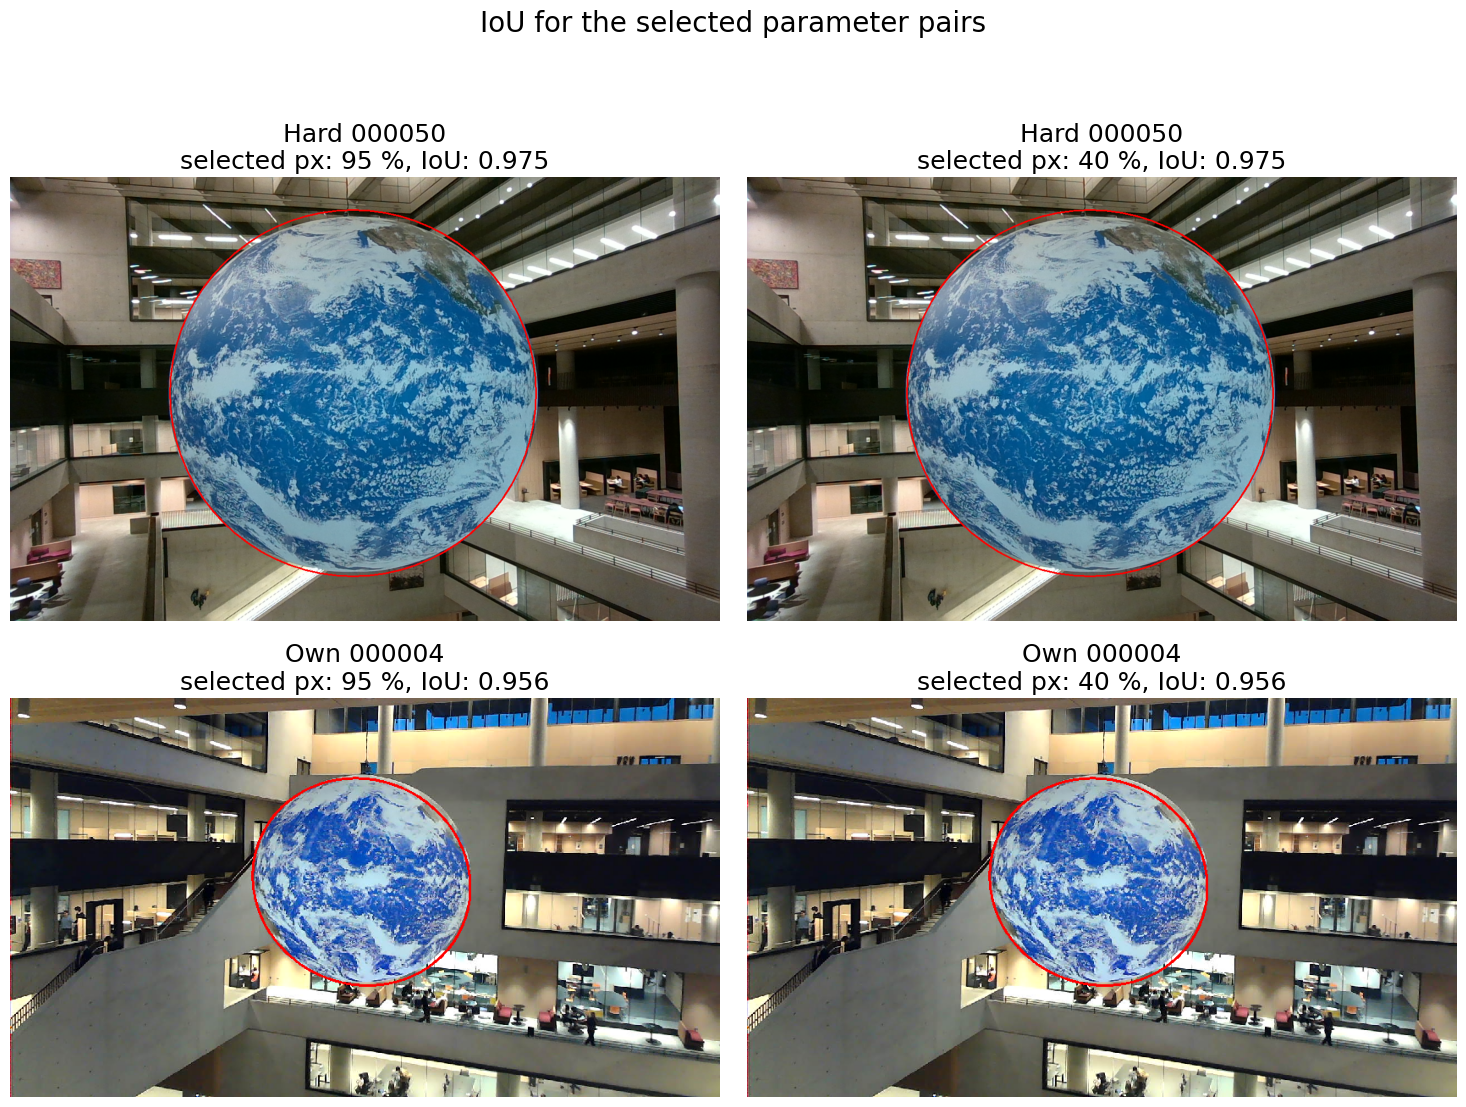

In [29]:
test_imgs = [
    ("Hard 000050", img_2, gt_mask_2),
    ("Own 000004", img_8, gt_mask_8)
]

def compute_rates(pred_mask, gt_mask):

    gt = gt_mask > 0

    pred = pred_mask > 0

    TP = np.logical_and(pred, gt).sum()
    FP = np.logical_and(pred, ~gt).sum()
    FN = np.logical_and(~pred, gt).sum()
    TN = np.logical_and(~pred, ~gt).sum()

    IoU = TP / (TP + FP + FN)
    return IoU

context_settings = {
    'font.size': 18,
    'axes.titlesize': 18,
    'axes.labelsize': 18
}

with plt.rc_context(context_settings):

    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    # fig.subplots_adjust(wspace=0.15, hspace=0.25)
    fig.suptitle("IoU for the selected parameter pairs", fontsize=20)

    WS_T = 135

    for row, (title, bgr_img, gt_mask) in enumerate(test_imgs):
        
        # Run YOUR watershed exactly as written above
        overlay, ao_mask, ws_mask, rg_mask, km_mask = combined_segmentation(bgr_img.copy(), 135, 95)
        overlay1, ao_mask1, ws_mask1, rg_mask1, km_mask1 = combined_segmentation(bgr_img.copy(), 135, 40)

        IoU = compute_rates(ao_mask, gt_mask)
        IoU1 = compute_rates(ao_mask1, gt_mask)

        # Plot original
        axes[row, 0].imshow(overlay)
        axes[row, 0].set_title(f"{title}\nselected px: 95 %, IoU: {np.round(IoU, 3)}")
        axes[row, 0].axis("off")

        # Plot watershed overlay
        axes[row, 1].imshow(overlay1)
        axes[row, 1].set_title(f"{title}\nselected px: 40 %, IoU: {np.round(IoU1, 3)}")
        axes[row, 1].axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()